# Checkpoint image codec trial

Select the existing `dip-project1` kernel. In the next cell, set `RUN_NAME` to the exact folder name under `DIP_RUNS_ROOT` or the repository's `runs` folder. Choose `CHECKPOINT_NAME` as `latest.pt` to use the latest training state or `best.pt` to use the lowest-validation-loss state when available. The notebook uses the same Kodak image, `kodim20.png`, for each run. The source checkpoint is loaded on CPU and is not modified.

Kodak is reserved for final evaluation, not training or model selection.

In [ ]:
RUN_NAME = "N_128_M_192-20261126-163934"  # Exact run-folder name under RUNS_ROOT
CHECKPOINT_NAME = "latest.pt"  # Use "best.pt" when the run has a best-validation checkpoint

In [11]:
import os
import sys
from pathlib import Path

if os.name == "nt":
    library_bin = Path(sys.prefix) / "Library" / "bin"
    path_entries = os.environ.get("PATH", "").split(os.pathsep)
    if library_bin.is_dir() and os.path.normcase(os.path.normpath(path_entries[0])) != os.path.normcase(str(library_bin)):
        os.environ["PATH"] = str(library_bin) + os.pathsep + os.environ.get("PATH", "")

current = Path.cwd().resolve()
REPOSITORY = next(
    (path for path in (current, *current.parents) if (path / "src" / "settings.py").is_file()),
    None,
)
if REPOSITORY is None:
    raise RuntimeError("Open this notebook from the project or set the working directory to the project root")
sys.path.insert(0, str(REPOSITORY / "src"))

from data.paths import KODAK_DIR

RUNS_ROOT = Path(os.environ.get("DIP_RUNS_ROOT", REPOSITORY / "runs"))

RUN_DIR = RUNS_ROOT / RUN_NAME
if not RUN_DIR.is_dir():
    available_runs = sorted(path.name for path in RUNS_ROOT.iterdir() if path.is_dir()) if RUNS_ROOT.is_dir() else []
    raise FileNotFoundError(f"Run '{RUN_NAME}' not found under {RUNS_ROOT}. Available runs: {available_runs}")

CHECKPOINT_PATH = RUN_DIR / "checkpoints" / CHECKPOINT_NAME
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint '{CHECKPOINT_NAME}' not found in run '{RUN_NAME}'")

IMAGE_PATH = KODAK_DIR / "kodim20.png"
if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f"Kodak image not found: {IMAGE_PATH}; check DIP_DATA_ROOT")
print(f"Selected run: {RUN_NAME}")
print(f"Selected checkpoint: {CHECKPOINT_PATH}")
print(f"Selected Kodak image: {IMAGE_PATH}")

Selected run: N_128_M_192-20261126-163934
Selected checkpoint: C:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\runs\N_128_M_192-20261126-163934\checkpoints\latest.pt
Selected Kodak image: C:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\data\kodak\kodim20.png


## Load and inspect

The image is converted to RGB; original dimensions are preserved.

Checkpoint: C:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\runs\N_128_M_192-20261126-163934\checkpoints\latest.pt
Model: N=128, M=192
Image: 768 x 512


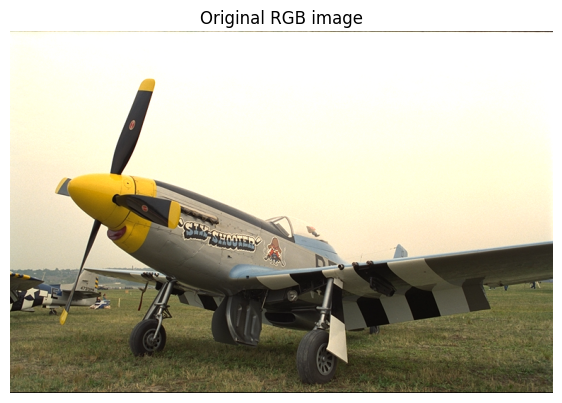

In [12]:
import matplotlib.pyplot as plt
from PIL import Image
from codec.inference import (
    load_codec, encode_image, decode_image, image_metrics, export_codec_checkpoint,
)

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Select a run with a checkpoint: {CHECKPOINT_PATH}")
if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f"Select an existing image: {IMAGE_PATH}")

model, settings = load_codec(CHECKPOINT_PATH)
with Image.open(IMAGE_PATH) as source:
    original = source.convert("RGB")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Model: N={settings.num_channels}, M={settings.latent_channels}")
print(f"Image: {original.width} x {original.height}")
plt.figure(figsize=(7, 7))
plt.imshow(original)
plt.title("Original RGB image")
plt.axis("off")
plt.show()

## Encode and decode

Actual BPP counts the header and both encoded streams, divided by the original image pixel count; it assumes the decoder already has the model and does not include checkpoint size. PSNR compares 8-bit RGB pixels after decoding; this is a single-image trial, not a dataset benchmark.

Original file size: 492,462 bytes
Encoded size: 23,520 bytes
Actual coded BPP: 0.4785
RGB PSNR: 18.97 dB


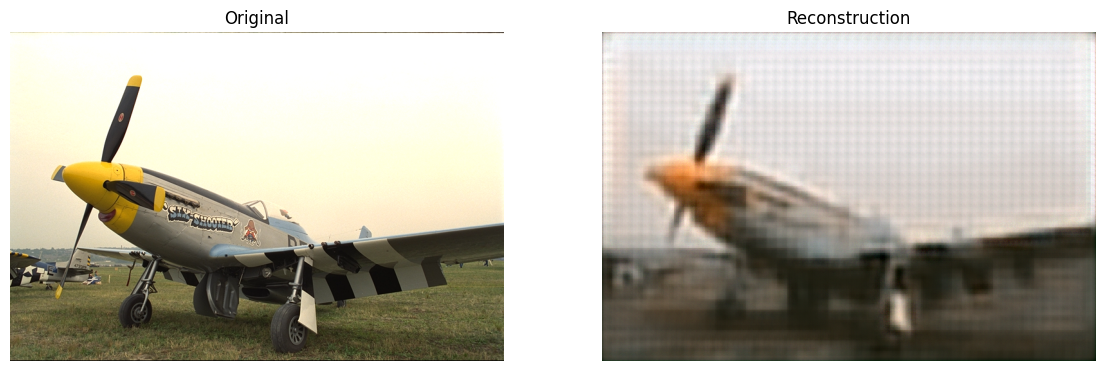

In [13]:
bitstream = encode_image(model, original)
reconstruction = decode_image(model, bitstream)
metrics = image_metrics(original, reconstruction, bitstream)
print(f"Original file size: {IMAGE_PATH.stat().st_size:,} bytes")
print(f"Encoded size: {metrics['bytes']:,} bytes")
print(f"Actual coded BPP: {metrics['bpp']:.4f}")
print(f"RGB PSNR: {metrics['psnr_db']:.2f} dB")

figure, axes = plt.subplots(1, 2, figsize=(14, 7))
for axis, image, title in zip(axes, (original, reconstruction), ("Original", "Reconstruction")):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
plt.show()